In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("msambare/fer2013")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fer2013' dataset.
Path to dataset files: /kaggle/input/fer2013


Found 28709 files belonging to 7 classes.
Using 22968 files for training.
Found 7178 files belonging to 7 classes.
Using 1435 files for validation.
Emotion Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Epoch 1/5
718/718 ━━━━━━━━━━━━━━━━━━━━ 86s 118ms/step - accuracy: 0.3178 - loss: 1.7105 - val_accuracy: 0.4000 - val_loss: 1.5459
Epoch 2/5
718/718 ━━━━━━━━━━━━━━━━━━━━ 65s 91ms/step - accuracy: 0.4042 - loss: 1.5431 - val_accuracy: 0.4383 - val_loss: 1.4539
Epoch 3/5
718/718 ━━━━━━━━━━━━━━━━━━━━ 64s 89ms/step - accuracy: 0.4405 - loss: 1.4554 - val_accuracy: 0.4718 - val_loss: 1.3787
Epoch 4/5
718/718 ━━━━━━━━━━━━━━━━━━━━ 83s 90ms/step - accuracy: 0.4608 - loss: 1.3971 - val_accuracy: 0.4801 - val_loss: 1.3562
Epoch 5/5
718/718 ━━━━━━━━━━━━━━━━━━━━ 63s 88ms/step - accuracy: 0.4786 - loss: 1.3532 - val_accuracy: 0.5003 - val_loss: 1.3326
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.5003 - loss: 1.3326
Test Accuracy: 50.03484487533569 %


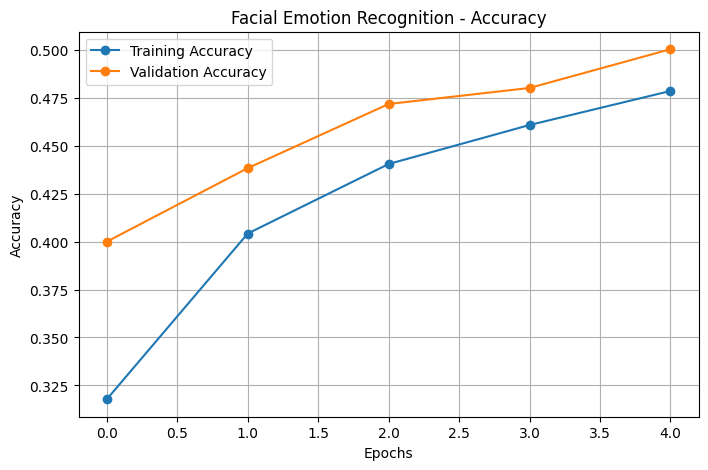

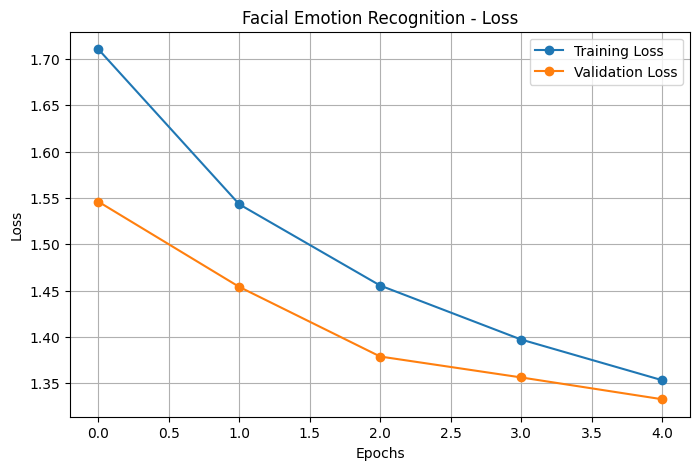

In [4]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
import os

# Dataset path (Using the actual downloaded path)
path = "/kaggle/input/fer2013"

# Check if train/test directories exist inside the dataset path
if os.path.exists(os.path.join(path, 'train')):
    train_path = os.path.join(path, 'train')
    test_path = os.path.join(path, 'test')
else:
    train_path = path
    test_path = path

# Load training dataset (80%)
train = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(48, 48),
    color_mode="grayscale",
    batch_size=32
)

# Load validation dataset (20%)
test = tf.keras.utils.image_dataset_from_directory(
    test_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(48, 48),
    color_mode="grayscale",
    batch_size=32
)

# Detect emotion classes
num_classes = len(train.class_names)
print("Emotion Classes:", train.class_names)

# Build CNN Model
model = models.Sequential([
    layers.Input(shape=(48, 48, 1)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(num_classes, activation='softmax')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(
    train,
    validation_data=test,
    epochs=5
)

# Evaluate model
loss, accuracy = model.evaluate(test)

print("Test Accuracy:", accuracy * 100, "%")

# Plot Accuracy Graph
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'],
         label='Training Accuracy', marker='o')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy', marker='o')

plt.title('Facial Emotion Recognition - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Plot Loss Graph
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'],
         label='Training Loss', marker='o')

plt.plot(history.history['val_loss'],
         label='Validation Loss', marker='o')

plt.title('Facial Emotion Recognition - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()